打开 Jupyter Notebook，新建 notebooks/titanic_analysis.ipynb。每个单元格按顺序运行。

In [3]:
# 加载安装包
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置可视化风格
sns.set_theme(style="whitegrid")
%matplotlib inline

# 加载数据
df = pd.read_csv("C:\\Users\\YXC23\\Desktop\\titanic\\data\\train.csv")
print('数据集的形状:', df.shape)
df.head()

数据集的形状: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


数据清洗前的“体检”步骤。

In [6]:
# 查看每列数据类型和非空数量
df.info()

# 查看数值型字段的统计摘要
df.describe()

# 查看每列缺失值数量和占比
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'缺失数量': missing, '缺失占比（%）': missing_pct.round(2)})
missing_df[missing_df['缺失数量'] > 0]

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,缺失数量,缺失占比（%）
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


数据清洗

In [10]:
# 丢弃无用列
df.dropna(subset = ['Embarked'], inplace = True)
df.reset_index(inplace = True, drop = True)

# 处理Embarked损失（2条）
df['Age'] = df['Age'].fillna(df['Age'].median())

# 检查清洗结果
print('清洗后的数据：')
print(df.isnull().sum())
print('\n数据形状:', df.shape)

清洗后的数据：
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

数据形状: (889, 9)


原始字段不够用，我们需要“造”一些更有信息量的特征。

In [11]:
# 从姓名提取称呼
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
print(df['Title'].value_counts())

# 把罕见称呼合并
rare_titles = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

# 创建家庭规模，是否独自出行
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 对分类变量做数值编码
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df = pd.get_dummies(df, columns=['Title'], prefix='Title')

Title
Mr          517
Miss        181
Mrs         124
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


探索性数据分析（EDA）

整体生存率： 38.25%


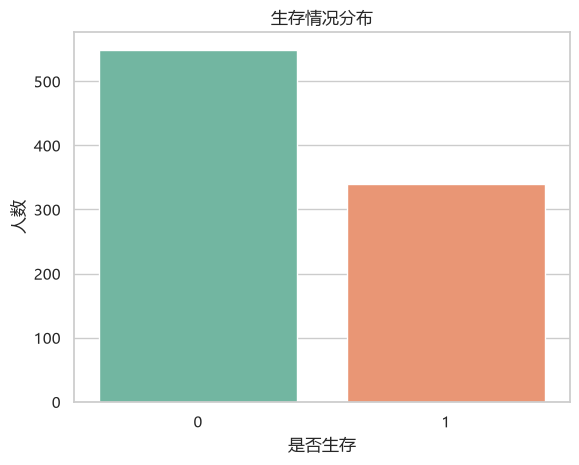

In [14]:
# 图1：整体生存率
survival_rate = df['Survived'].mean()
print(f'整体生存率： {survival_rate:.2%}')

# 1. 解决中文显示
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 2. 正确的 countplot 写法
sns.countplot(x='Survived', data=df, hue='Survived', palette='Set2', legend=False)

plt.title('生存情况分布')
plt.xlabel('是否生存')
plt.ylabel('人数')
plt.show()

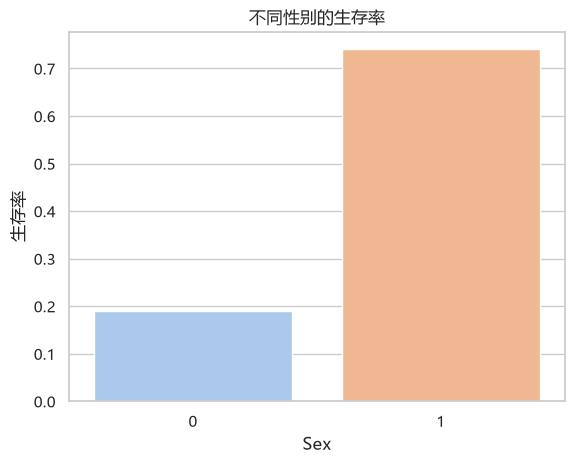

In [19]:
# 图2：性别与生存率
sns.barplot(
    x='Sex',
    y='Survived',
    data=df,
    hue='Sex',
    palette='pastel',
    legend=False,
    errorbar=None
)
plt.title('不同性别的生存率')
plt.ylabel('生存率')
plt.show()

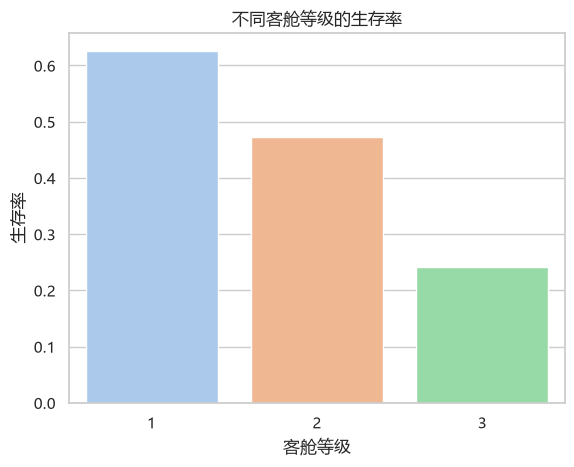

In [21]:
# 图3：客舱等级与生存率
sns.barplot(x='Pclass', y='Survived', data=df, hue='Pclass', palette='pastel', legend=False, errorbar=None)
plt.title('不同客舱等级的生存率')
plt.xlabel('客舱等级')
plt.ylabel('生存率')
plt.show()

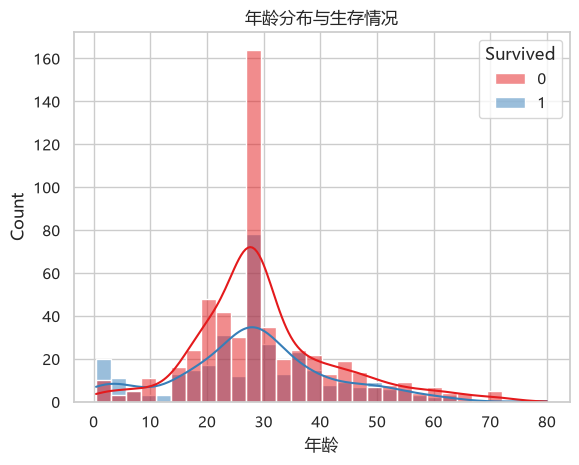

In [22]:
# 图4：年龄分布与生存情况
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, palette='Set1')
plt.title('年龄分布与生存情况')
plt.xlabel('年龄')
plt.show()

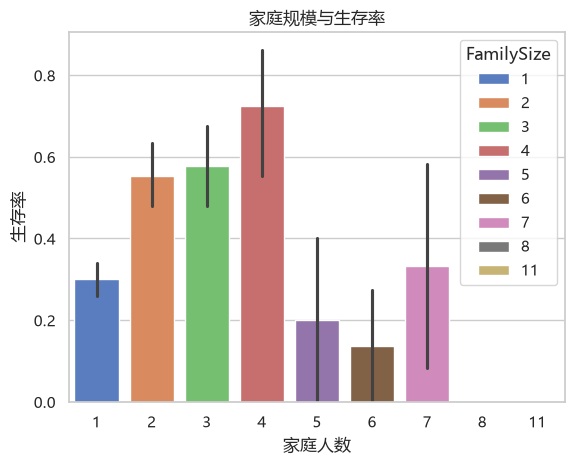

In [24]:
# 图5：家庭规模与生存率
sns.barplot(x='FamilySize', y='Survived', hue='FamilySize', data=df, palette='muted')
plt.title('家庭规模与生存率')
plt.xlabel('家庭人数')
plt.ylabel('生存率')
plt.show()

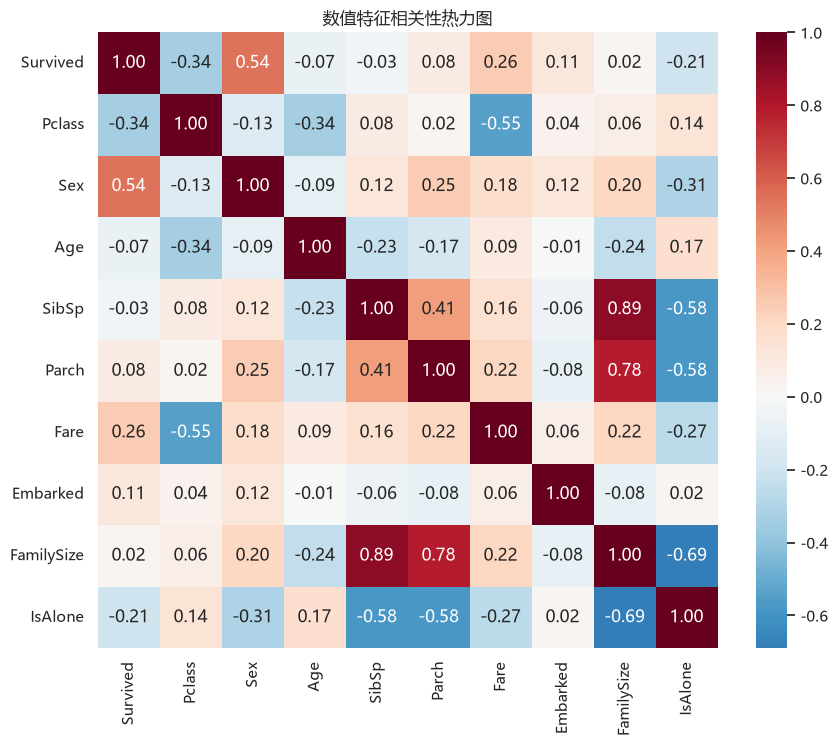

In [25]:
# 图6：相关性热力图
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('数值特征相关性热力图')
plt.show()

In [30]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 准备特征和目标
feature_cols = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone'] + [c for c in df.columns if c.startswith('Title_')]
X = df[feature_cols]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_predict = model.predict(X_test)
print(f'准确率：{accuracy_score(y_test, y_predict):.4f}%')
print('\n分类报告：')
print(classification_report(y_test, y_predict))

准确率：0.8146%

分类报告：
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       109
           1       0.74      0.80      0.77        69

    accuracy                           0.81       178
   macro avg       0.80      0.81      0.81       178
weighted avg       0.82      0.81      0.82       178

